In [384]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)


In [385]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)

In [386]:
df["articles"].describe()
df = df.join(df_sentiment)
df["vix"] = df["adj close"].apply(np.int)
df["vix_ln_return"]=np.log(df["vix"]/df["vix"].shift(1))
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
# df['date'] = pd.date_range(start='25/9/2019', periods=len(df), freq='D')

In [387]:
df

,close,adj close,articles,compound,neg,neu,pos,sentiment,sentiment_complementary,vix,vix_ln_return,sentiment_ewm
2019-09-25,15.960000,15.960000,FDA Approves Abbott's Low Dose Recharge-Free S...,1.0,0.015,0.879,0.106,87.603306,12.396694,15,NaN,87.603306
2019-09-26,16.070000,16.070000,"FDA Approves Abbott's ""Low Dose,"" Recharge-Fre...",1.0,0.022,0.859,0.118,84.285714,15.714286,16,0.064539,85.865520
2019-09-27,17.219999,17.219999,New Data Demonstrate Strong Outcomes for Abbot...,0.9998,0.033,0.862,0.105,76.086957,23.913043,17,0.060625,82.290879
2019-09-30,16.240000,16.240000,"ParTech, Inc. completed the acquisition of ass...",1.0,0.024,0.849,0.127,84.105960,15.894040,16,-0.060625,82.811429
2019-10-01,18.559999,18.559999,"Accenture plc Presents at All Day DevOps, Nov-...",0.9999,0.021,0.901,0.078,78.787879,21.212121,18,0.117783,81.846518
...,...,...,...,...,...,...,...,...,...,...,...,...
2021-07-12,16.170000,16.170000,3M Oral Care Introduces Next-Generation Clear ...,0.9999,0.013,0.848,0.138,91.390728,8.609272,16,0.000000,88.107165
2021-07-13,17.120001,17.120001,3M Announces Upcoming Investor Event. ST. PAUL...,1.0,0.011,0.843,0.146,92.993631,7.006369,17,0.060625,88.551389
2021-07-14,16.330000,16.330000,Cybersecurity Executive Rick Driggers Joins Ac...,0.9999,0.01,0.874,0.116,92.063492,7.936508,16,-0.060625,88.870672
2021-07-15,17.010000,17.010000,Air Products Declares Quarterly Dividend. LEHI...,1.0,0.016,0.817,0.166,91.208791,8.791209,17,0.060625,89.083228


In [388]:
df["sentiment"]

2019-09-25    87.603306
2019-09-26    84.285714
2019-09-27    76.086957
2019-09-30    84.105960
2019-10-01    78.787879
                ...    
2021-07-12    91.390728
2021-07-13    92.993631
2021-07-14    92.063492
2021-07-15    91.208791
2021-07-16    80.165289
Name: sentiment, Length: 456, dtype: float64

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.


<AxesSubplot:xlabel='vix', ylabel='sentiment'>

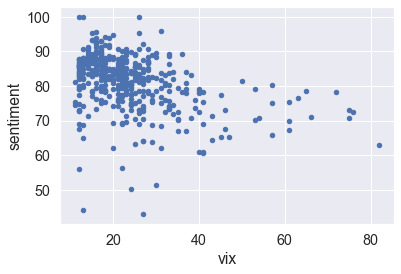

In [389]:
df.plot(x="vix", y="sentiment", kind="scatter")

In [390]:
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

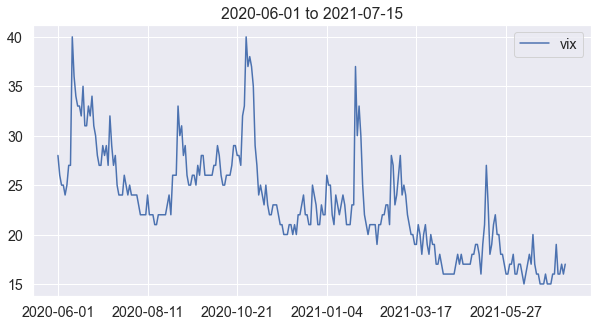

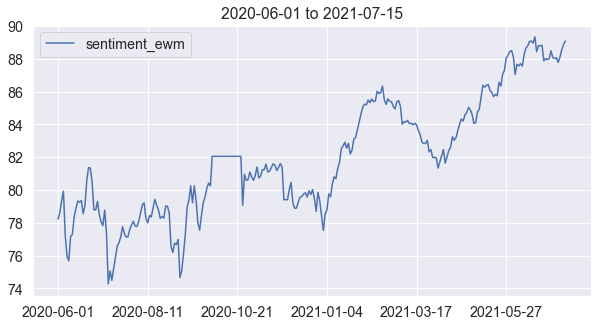

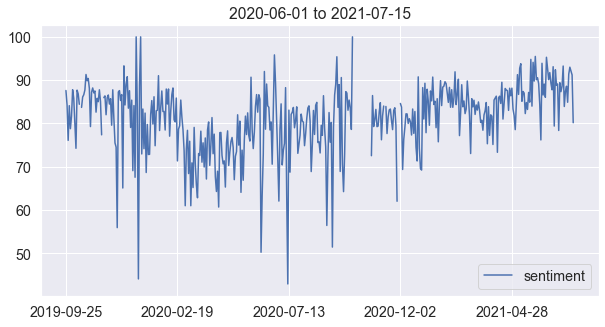

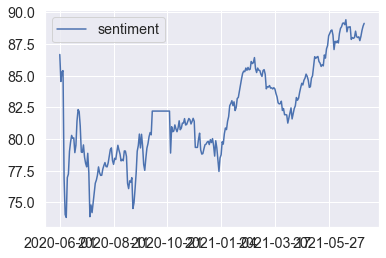

In [391]:

# dfplot = df_part1[['VIX']].plot(figsize=(10, 5),title='2019-09-25 to 2020-02-14')
# fig = dfplot.get_figure()

# dfplot = df_part2[['VIX']].plot(figsize=(10, 5),title='2020-02-15 to 2020-05-31')
# fig = dfplot.get_figure()

dfplot = df_part3[['vix']].plot(figsize=(10, 5),title='2020-06-01 to 2021-07-15')
fig = dfplot.get_figure()



df_part3[['sentiment']] =df_part3[['sentiment']].apply(pd.to_numeric)
df_part3[['sentiment_ewm']].plot(figsize=(10, 5),title='2020-06-01 to 2021-07-15')
dfplot = df[['sentiment']].plot(figsize=(10, 5),title='2020-06-01 to 2021-07-15')
fig = dfplot.get_figure()

fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/sentiment.png")
df_part3[['sentiment']].ewm(span=20).mean().plot()
fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/sentiment_ewm.png")



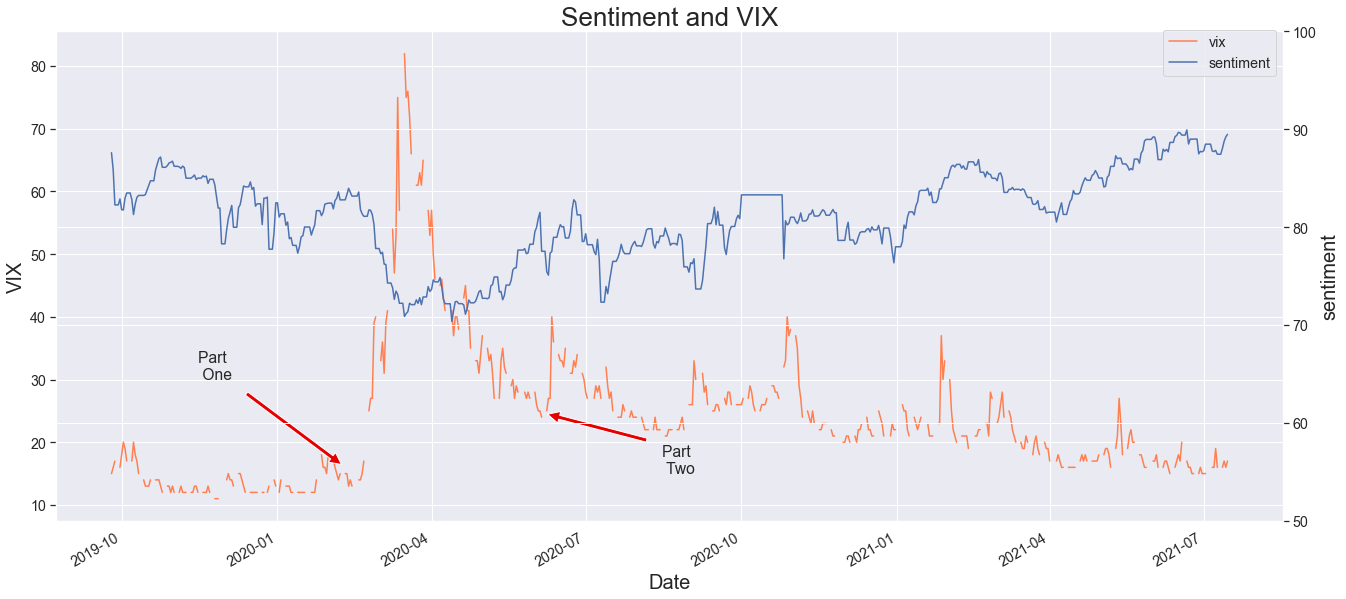

In [392]:
import matplotlib.pyplot as plt
import datetime as dt
import matplotlib.dates as mdates
df1 = df
idx = pd.date_range('2019-09-25', '2021-07-15')
df1.index = pd.DatetimeIndex(df1.index)
df1 = df1.reindex(idx, fill_value=np.NaN)


#df[['sentiment']] = df[['sentiment']].ewm(span=20)
fig, ax1 = plt.subplots(figsize=(22,10))
l1 = ax1.plot(df1[['vix']], color='#ff7f50')
ax1.set_xlabel("Date",fontsize=20)
ax1.set_title("Sentiment and VIX", size=26)
ax1.set_ylabel("VIX", size=20)
# index=['sentiment', 'VIX']

starting_date = dt.datetime(2019, 11, 15)
starting_date1 = mdates.date2num(starting_date)
pointing_arrow =dt.datetime(2020, 2, 15)
pointing_arrow1 = mdates.date2num(pointing_arrow)
ax1.annotate('Part \n One', xy=(pointing_arrow1, 15), xytext=(starting_date1,30),
            arrowprops=dict(facecolor='#e50000', shrink=0.1),
            )

starting_date2 = dt.datetime(2020, 8, 15)
starting_date3 = mdates.date2num(starting_date2)
pointing_arrow3 =dt.datetime(2020, 6, 1)
pointing_arrow4 = mdates.date2num(pointing_arrow3)
ax1.annotate('Part \n Two', xy=(pointing_arrow4, 25), xytext=(starting_date3,15),
            arrowprops=dict(facecolor='#e50000', shrink=0.1),
            )
#ax1.axhline(y=15, color='b', linestyle='--')
# starting_date = dt.datetime(2020, 2, 15)
# starting_date1 = mdates.date2num(starting_date)
# ax1.axvline(starting_date1, 0, 1, color='b', linestyle='--')
# starting_date2 = dt.datetime(2020, 6, 1)
# starting_date3 = mdates.date2num(starting_date2)
# ax1.axvline(starting_date3, 0, 1, color='b', linestyle='--')

ax2 = ax1.twinx()
l2 = ax2.plot(df1[['sentiment']].ewm(span=20).mean())#, color='#f97306')# color='#e50000')
ax2.set_ylim([50, 100])
ax2.set_ylabel("sentiment", size=20)

labels=['vix', 'sentiment']
fig.legend([l1, l2], labels=labels, loc='right', bbox_to_anchor=(0.9, 0.85))

fig.autofmt_xdate()
fig = ax2.get_figure()

#fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/sentimentVIX.png")

In [393]:
# import matplotlib.pyplot as plt
# import datetime as dt
# import matplotlib.dates as mdates
# df1_part3 = df_part3
# idx = pd.date_range('2020-06-01', '2021-07-15')
# df1_part3.index = pd.DatetimeIndex(df1.index)
# df1_part3 = df1_part3.reindex(idx, fill_value=np.NaN)

# fig, ax1 = plt.subplots(figsize=(20,10))
# l1 = ax1.plot(df1_part3['vix'], color='#ff7f50')
# ax1.set_xlabel("Date",fontsize=20)
# ax1.set_title("Sentiment and VIX \n 2020-06-01 to 2021-07-16", size=26)
# ax1.set_ylabel("VIX", size=20)

# ax2 = ax1.twinx()
# l2 = ax2.plot(df1_part3['sentiment'].ewm(span=20).mean())#, color='#f97306')# color='#e50000')
# ax2.set_ylim([50, 100])
# ax2.set_ylabel("sentiment", size=20)

# labels=['vix', 'sentiment']
# fig.legend([l1, l2], labels=labels, loc='right', bbox_to_anchor=(0.9, 0.85))

# fig.autofmt_xdate()
# fig = ax2.get_figure()

# fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/sentimentVIXpart3.png")

In [394]:
df_part3.index

Index(['2020-06-01', '2020-06-02', '2020-06-03', '2020-06-04', '2020-06-05',
       '2020-06-08', '2020-06-09', '2020-06-10', '2020-06-11', '2020-06-12',
       ...
       '2021-07-01', '2021-07-02', '2021-07-06', '2021-07-07', '2021-07-08',
       '2021-07-09', '2021-07-12', '2021-07-13', '2021-07-14', '2021-07-15'],
      dtype='object', length=284)

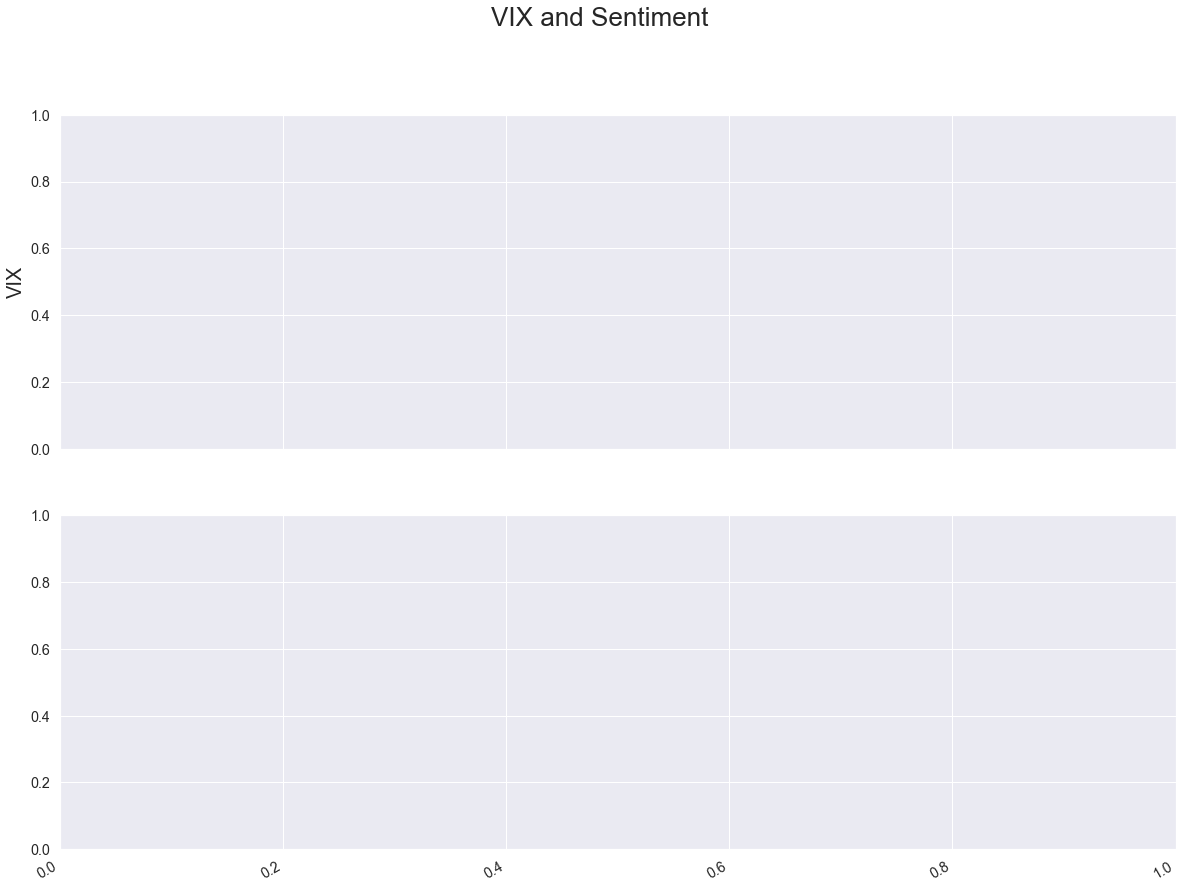

In [395]:
# import matplotlib.pyplot as plt
# import datetime as dt
# import matplotlib.dates as mdates
# df1 = df
# idx = pd.date_range('2019-09-25', '2021-07-15')
# df1.index = pd.DatetimeIndex(df1.index)
# df1 = df1.reindex(idx, fill_value=np.NaN)

df1_part1 = df_part1
df1_part2 = df_part2
df1_part3 = df_part3

idx = pd.date_range('2019-09-25', '2020-02-14')
df1_part1.index = pd.DatetimeIndex(df1_part1.index)
df1_part1 = df1_part1.reindex(idx, fill_value=np.NaN)
idx = pd.date_range('2020-02-15', '2020-05-31')
df1_part2.index = pd.DatetimeIndex(df1_part2.index)
df1_part2 = df1_part2.reindex(idx, fill_value=np.NaN)
idx = pd.date_range('2020-06-01', '2021-07-15')
df1_part3.index = pd.DatetimeIndex(df1_part3.index)
df1_part3 = df1_part3.reindex(idx, fill_value=np.NaN)

# dfplot = df_part1[['VIX']].plot(figsize=(10, 5),title='2019-09-14 to 2020-02-14')
# fig = dfplot.get_figure()   

# dfplot = df_part2[['VIX']].plot(figsize=(10, 5),title='2019-09-25 to 2020-02-14')
# fig = dfplot.get_figure()   

# dfplot = df_part3[['VIX']].plot(figsize=(10, 5),title='2019-09-25 to 2020-02-14')
# fig = dfplot.get_figure()   

fig, axs = plt.subplots(2,figsize=(20,15))
fig.suptitle('VIX and Sentiment', size=26)
fig.autofmt_xdate()
# axs[0].set_ylabel("sentiment", size=20)
# axs[0].plot(df_part1[['sentiment']])
# axs[0].plot(df_part2[['sentiment']])
# axs[0].plot(df_part3[['sentiment']])
axs[0].set_ylabel("VIX", size=20)
labels=['2019-09-14 to 2020-02-14', '2020-02-15 to 2020-05-31', '2020-06-01 to 2021-07-15']

l1 = axs[0].plot(df1_part1[['vix']])
l2 = axs[0].plot(df1_part2[['vix']])
l3 = axs[0].plot(df1_part3[['vix']])
axs[0].legend([l1, l2, l3], labels=labels, loc='upper right')#, bbox_to_anchor='upper right')#(0.99, 0.85))

axs[1].set_ylabel("Sentiment EWM", size=20)
axs[1].plot(df1_part1[['sentiment_ewm']])
axs[1].plot(df1_part2[['sentiment_ewm']])
axs[1].plot(df1_part3[['sentiment_ewm']])
axs[1].legend([l1, l2, l3], labels=labels, loc='lower right')#, bbox_to_anchor=(0.99, 0.2))

# axs[0].set_ylabel("Sentiment", size=20)
# axs[0].plot(df_part1[['sentiment']])
# axs[0].plot(df_part2[['sentiment']])
# axs[0].plot(df_part3[['sentiment']])


# axs[0].labels()

#plt.subplot(121)
#plt.set_ylabel("VIX", size=20)

# plt.plot(df_part1[['VIX']])

# #plt.subplot(122)
# plt.plot(df_part2[['VIX']])
# # plt.subplot(123)
# plt.plot(df_part3[['VIX']])
# plt.axvspan(x='2020-02-15', color='b', linestyle='--')
starting_date = dt.datetime(2020, 2, 15)
starting_date1 = mdates.date2num(starting_date)
axs[0].axvline(starting_date1, 0, 1, color='b', linestyle='--')
plt.axvline(starting_date1, 0, 1, color='b', linestyle='--')

starting_date2 = dt.datetime(2020, 6, 1)
starting_date3 = mdates.date2num(starting_date2)
axs[0].axvline(starting_date3, 0, 1, color='b', linestyle='--')
plt.axvline(starting_date3, 0, 1, color='b', linestyle='--')



fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/VIXandSentimentSubplots.png")
plt.show()

# import datetime
# start_date = datetime.datetime(2020, 2, 15)
# end_date = datetime.datetime(2020, 6, 1)
# plt.axvspan(start_date, end_date, color='g', alpha=0.5, lw=0)
# fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/VIXandSentimentSubplots2.png")
# plt.show()

In [396]:
df_part3.index

DatetimeIndex(['2020-06-01', '2020-06-02', '2020-06-03', '2020-06-04',
               '2020-06-05', '2020-06-08', '2020-06-09', '2020-06-10',
               '2020-06-11', '2020-06-12',
               ...
               '2021-07-01', '2021-07-02', '2021-07-06', '2021-07-07',
               '2021-07-08', '2021-07-09', '2021-07-12', '2021-07-13',
               '2021-07-14', '2021-07-15'],
              dtype='datetime64[ns]', length=284, freq=None)

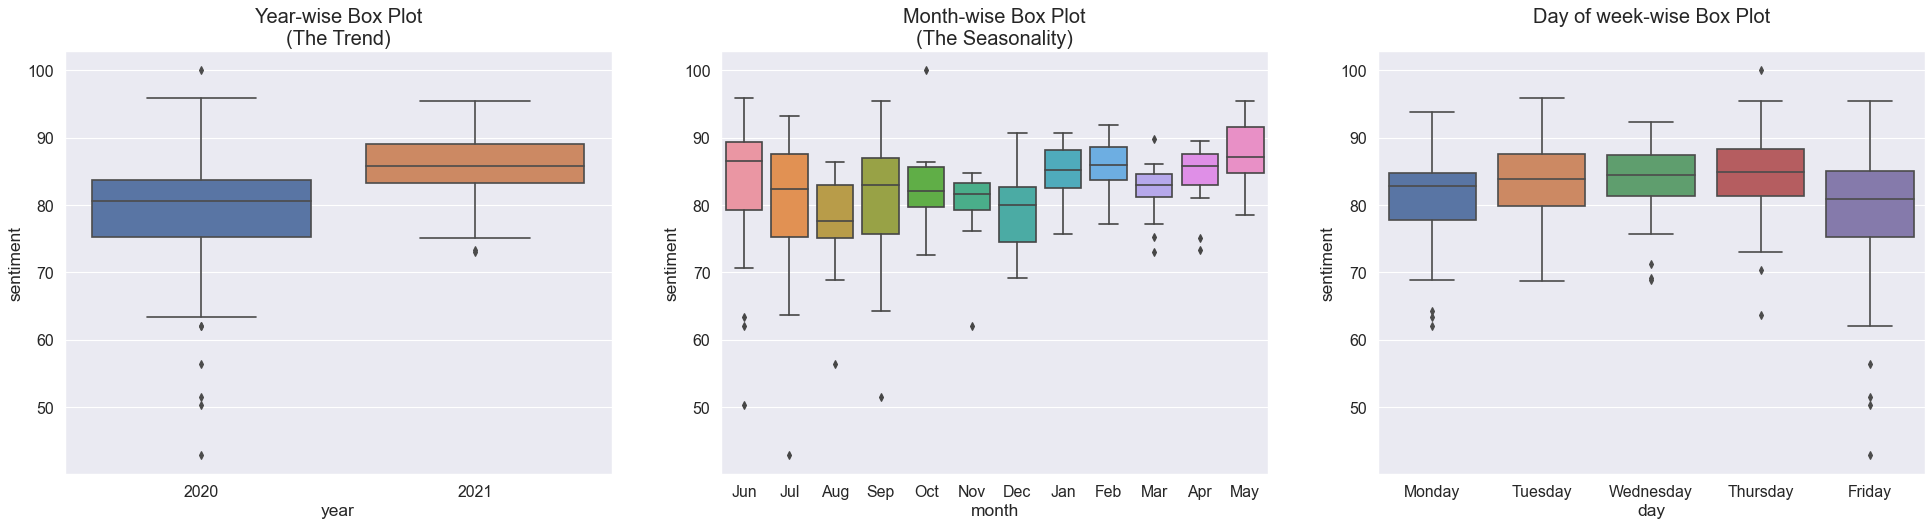

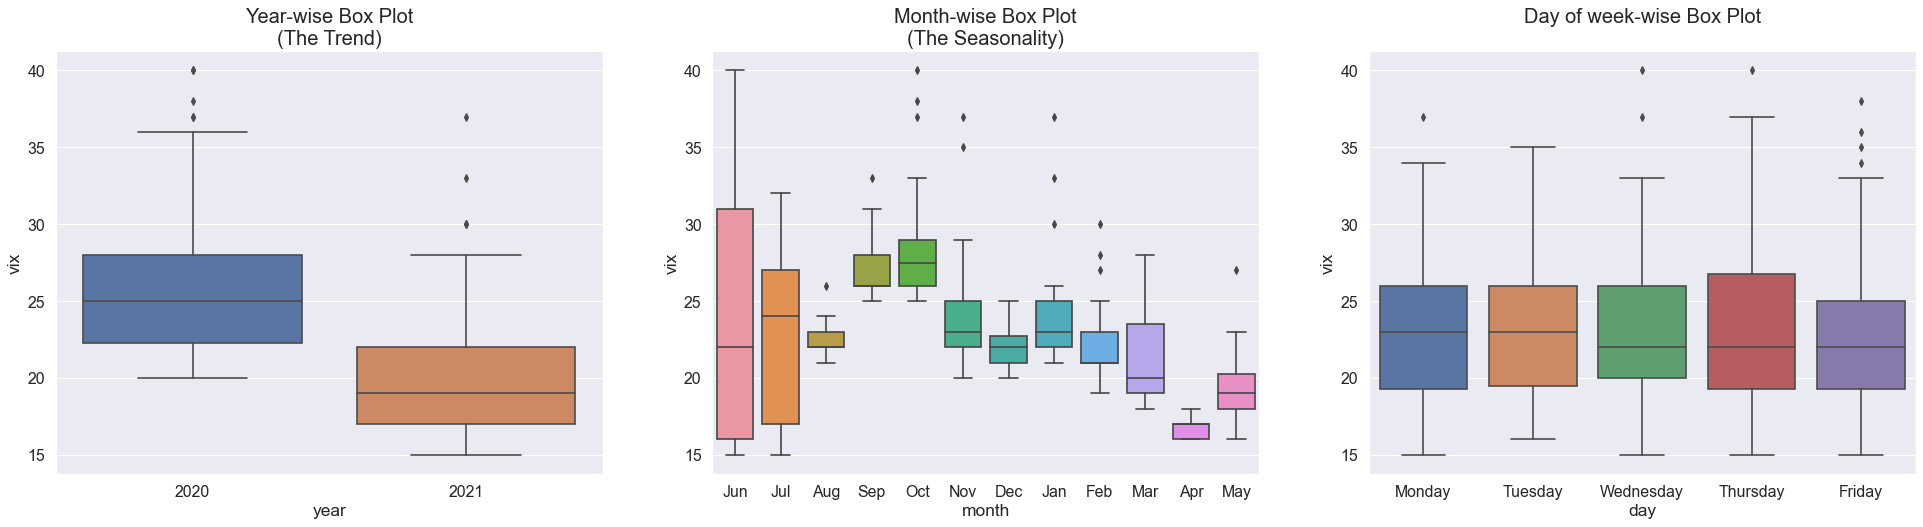

In [397]:
import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()]  #'Wednesday'


# Prepare data
df_part3['year'] = [d.year for d in df_part3.index]
df_part3['month'] = [d.strftime('%b') for d in df_part3.index]
df_part3['day'] = [d for d in df_part3.index.day_name()]
# # df_part3['date']
years = df_part3['year'].unique()

# Draw Plot
fig, axes = plt.subplots(1, 3, figsize=(30,7), dpi= 80)
sns.boxplot(x='year', y='sentiment', data=df_part3, ax=axes[0])
sns.boxplot(x='month', y='sentiment', data=df_part3, ax=axes[1])# data=df.loc[~df.year.isin([1991, 2008]), :])
sns.boxplot(x='day', y='sentiment', data=df_part3, ax=axes[2])# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
#plt.title("Sentiment Trend and Seasonality Analysis", fontsize=18); 
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
axes[2].set_title('Day of week-wise Box Plot\n', fontsize=18)

plt.show()

# Draw Plot
fig, axes = plt.subplots(1, 3, figsize=(30,7), dpi= 80)
sns.boxplot(x='year', y='vix', data=df_part3, ax=axes[0])
sns.boxplot(x='month', y='vix', data=df_part3, ax=axes[1])# data=df.loc[~df.year.isin([1991, 2008]), :])
sns.boxplot(x='day', y='vix', data=df_part3, ax=axes[2])# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
#plt.title("Sentiment Trend and Seasonality Analysis", fontsize=18); 
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
axes[2].set_title('Day of week-wise Box Plot\n', fontsize=18)

plt.show()

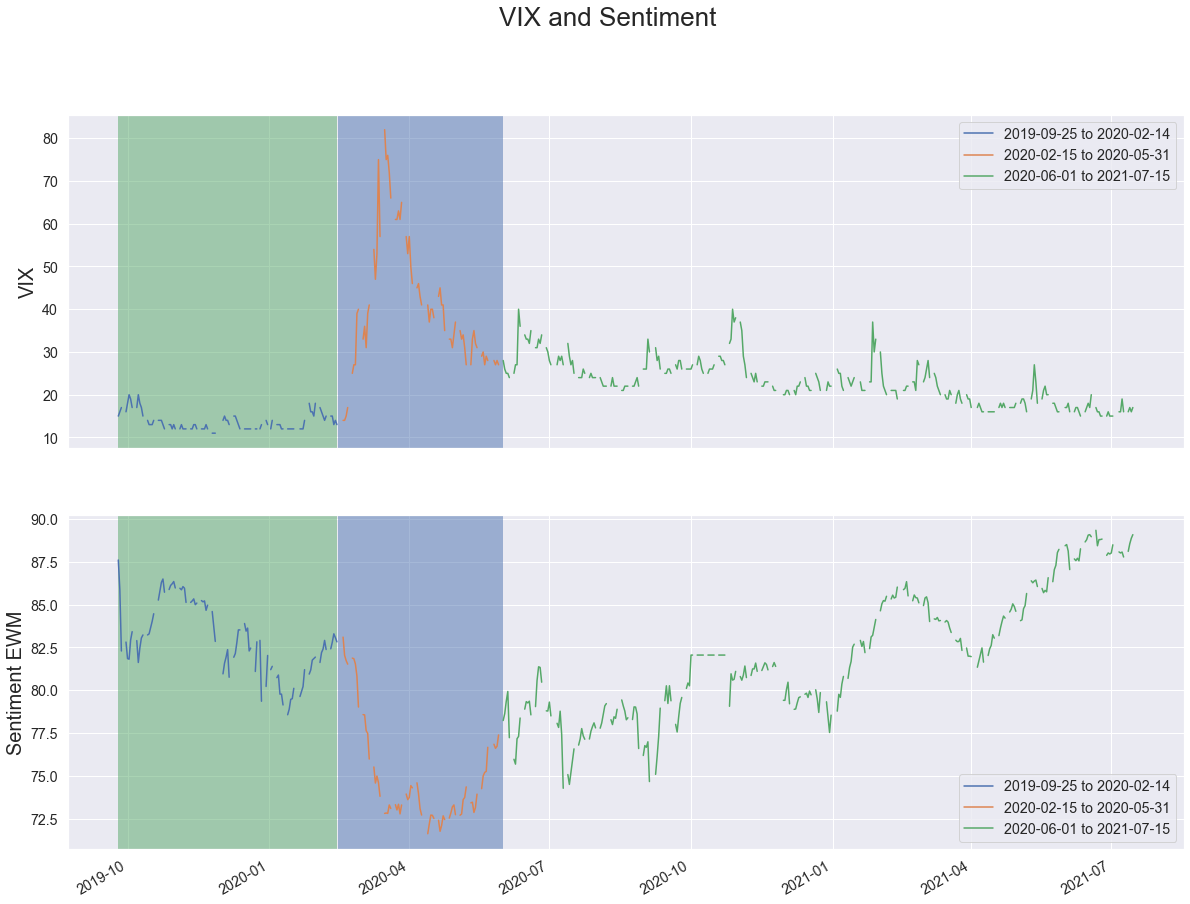

In [398]:
df1_part1 = df_part1
df1_part2 = df_part2
df1_part3 = df_part3

idx = pd.date_range('2019-09-25', '2020-02-14')
df1_part1.index = pd.DatetimeIndex(df1_part1.index)
df1_part1 = df1_part1.reindex(idx, fill_value=np.NaN)
idx = pd.date_range('2020-02-15', '2020-05-31')
df1_part2.index = pd.DatetimeIndex(df1_part2.index)
df1_part2 = df1_part2.reindex(idx, fill_value=np.NaN)
idx = pd.date_range('2020-06-01', '2021-07-15')
df1_part3.index = pd.DatetimeIndex(df1_part3.index)
df1_part3 = df1_part3.reindex(idx, fill_value=np.NaN)

fig, axs = plt.subplots(2,figsize=(20,15))
fig.suptitle('VIX and Sentiment', size=26)
fig.autofmt_xdate()
# axs[0].set_ylabel("sentiment", size=20)
# axs[0].plot(df_part1[['sentiment']])
# axs[0].plot(df_part2[['sentiment']])
# axs[0].plot(df_part3[['sentiment']])
axs[0].set_ylabel("VIX", size=20)
labels=['2019-09-25 to 2020-02-14', '2020-02-15 to 2020-05-31', '2020-06-01 to 2021-07-15']

l1 = axs[0].plot(df1_part1[['vix']])
l2 = axs[0].plot(df1_part2[['vix']])
l3 = axs[0].plot(df1_part3[['vix']])
axs[0].legend([l1, l2, l3], labels=labels, loc='upper right')#, bbox_to_anchor='upper right')#(0.99, 0.85))

axs[1].set_ylabel("Sentiment EWM", size=20)
axs[1].plot(df1_part1[['sentiment_ewm']])
axs[1].plot(df1_part2[['sentiment_ewm']])
axs[1].plot(df1_part3[['sentiment_ewm']])
axs[1].legend([l1, l2, l3], labels=labels, loc='lower right')#, bbox_to_anchor=(0.99, 0.2))

import datetime
start_date = datetime.datetime(2019, 9, 25)
end_date = datetime.datetime(2020, 2, 14)

start_date1 = datetime.datetime(2020, 2, 15)
end_date1 = datetime.datetime(2020, 6, 1)

plt.axvspan(start_date, end_date, color='g', alpha=0.5, lw=0)
axs[0].axvspan(start_date, end_date, color='g', alpha=0.5, lw=0)

plt.axvspan(start_date1, end_date1, color='b', alpha=0.5, lw=0)
axs[0].axvspan(start_date1, end_date1, color='b', alpha=0.5, lw=0)

fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/VIXandSentimentSubplots2.png")
plt.show()

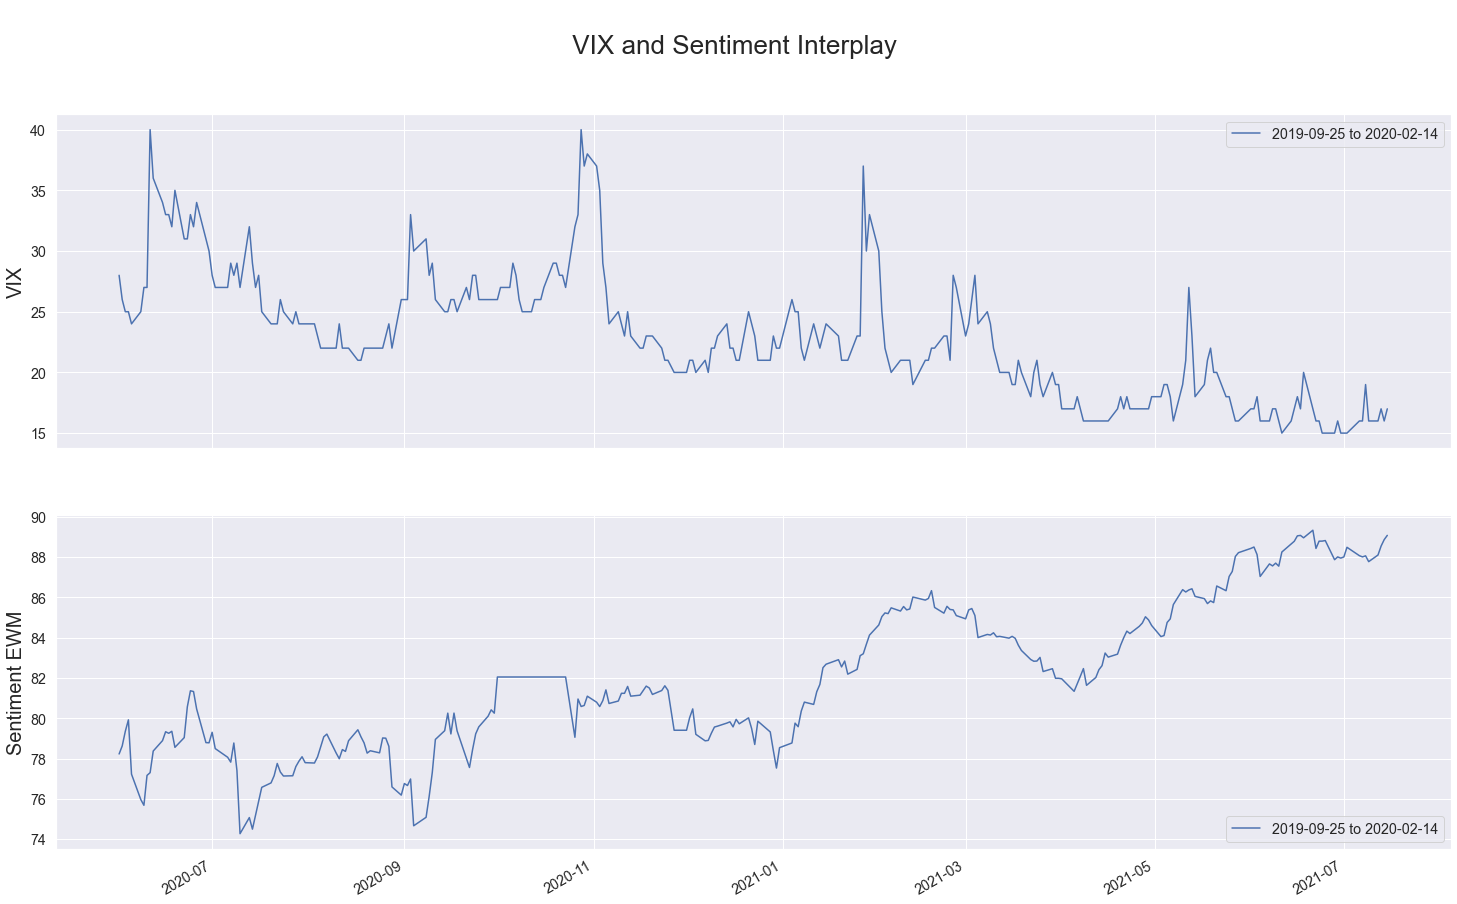

In [399]:
fig, axs = plt.subplots(2,figsize=(25,15))
fig.suptitle(' \n VIX and Sentiment Interplay', size=26)
fig.autofmt_xdate()
# axs[0].set_ylabel("sentiment", size=20)
# axs[0].plot(df_part1[['sentiment']])
# axs[0].plot(df_part2[['sentiment']])
# axs[0].plot(df_part3[['sentiment']])
axs[0].set_ylabel("VIX", size=20)
labels=['2019-09-25 to 2020-02-14', '2020-02-15 to 2020-05-31', '2020-06-01 to 2021-07-15']

l1 = axs[0].plot(df_part3[['vix']])
axs[0].legend([l1, l2, l3], labels=labels, loc='upper right')#, bbox_to_anchor='upper right')#(0.99, 0.85))

axs[1].set_ylabel("Sentiment EWM", size=20)

axs[1].plot(df_part3[['sentiment_ewm']])
axs[1].legend([l1, l2, l3], labels=labels, loc='lower right')#, bbox_to_anchor=(0.99, 0.2))

fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/VIXandSentimentSubplots3.png")
plt.show()

In [400]:
df[['vix', 'compound', 'neg', 'neu', 'pos', 'sentiment']]

,vix,compound,neg,neu,pos,sentiment
2019-09-25,15,1.0,0.015,0.879,0.106,87.603306
2019-09-26,16,1.0,0.022,0.859,0.118,84.285714
2019-09-27,17,0.9998,0.033,0.862,0.105,76.086957
2019-09-30,16,1.0,0.024,0.849,0.127,84.105960
2019-10-01,18,0.9999,0.021,0.901,0.078,78.787879
...,...,...,...,...,...,...
2021-07-12,16,0.9999,0.013,0.848,0.138,91.390728
2021-07-13,17,1.0,0.011,0.843,0.146,92.993631
2021-07-14,16,0.9999,0.01,0.874,0.116,92.063492
2021-07-15,17,1.0,0.016,0.817,0.166,91.208791


In [401]:
df_part3

,close,adj close,articles,compound,neg,neu,pos,sentiment,sentiment_complementary,vix,vix_ln_return,sentiment_ewm,year,month,day
2020-06-01,28.230000,28.230000,Abbvie Submits Regulatory Applications To FDA ...,0.9994,0.018,0.865,0.117,86.666667,13.333333,28,0.036368,78.231366,2020,Jun,Monday
2020-06-02,26.840000,26.840000,Bigfoot Biomedical® Closes Series C Financing ...,0.999,0.024,0.861,0.114,82.608696,17.391304,26,-0.074108,78.629305,2020,Jun,Tuesday
2020-06-03,25.660000,25.660000,3M Appoints Monish Patolawala As New Chief Fin...,0.9996,0.021,0.843,0.136,86.624204,13.375796,25,-0.039221,79.356114,2020,Jun,Wednesday
2020-06-04,25.809999,25.809999,Abbvie Says Rinvoq's Safety Profile Was Consis...,0.9997,0.022,0.847,0.131,85.620915,14.379085,25,0.000000,79.925642,2020,Jun,Thursday
2020-06-05,24.520000,24.520000,"Abbvie, Harbour Biomed, Utrecht University And...",0.7187,0.1,0.798,0.101,50.248756,49.751244,24,-0.040822,77.227742,2020,Jun,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-07-09,16.180000,16.180000,Accenture Completes Acquisition of Linkbynet f...,0.9992,0.021,0.862,0.118,84.892086,15.107914,16,-0.171850,87.778809,2021,Jul,Friday
2021-07-12,16.170000,16.170000,3M Oral Care Introduces Next-Generation Clear ...,0.9999,0.013,0.848,0.138,91.390728,8.609272,16,0.000000,88.107165,2021,Jul,Monday
2021-07-13,17.120001,17.120001,3M Announces Upcoming Investor Event. ST. PAUL...,1.0,0.011,0.843,0.146,92.993631,7.006369,17,0.060625,88.551389,2021,Jul,Tuesday
2021-07-14,16.330000,16.330000,Cybersecurity Executive Rick Driggers Joins Ac...,0.9999,0.01,0.874,0.116,92.063492,7.936508,16,-0.060625,88.870672,2021,Jul,Wednesday


In [402]:
df_part3

,close,adj close,articles,compound,neg,neu,pos,sentiment,sentiment_complementary,vix,vix_ln_return,sentiment_ewm,year,month,day
2020-06-01,28.230000,28.230000,Abbvie Submits Regulatory Applications To FDA ...,0.9994,0.018,0.865,0.117,86.666667,13.333333,28,0.036368,78.231366,2020,Jun,Monday
2020-06-02,26.840000,26.840000,Bigfoot Biomedical® Closes Series C Financing ...,0.999,0.024,0.861,0.114,82.608696,17.391304,26,-0.074108,78.629305,2020,Jun,Tuesday
2020-06-03,25.660000,25.660000,3M Appoints Monish Patolawala As New Chief Fin...,0.9996,0.021,0.843,0.136,86.624204,13.375796,25,-0.039221,79.356114,2020,Jun,Wednesday
2020-06-04,25.809999,25.809999,Abbvie Says Rinvoq's Safety Profile Was Consis...,0.9997,0.022,0.847,0.131,85.620915,14.379085,25,0.000000,79.925642,2020,Jun,Thursday
2020-06-05,24.520000,24.520000,"Abbvie, Harbour Biomed, Utrecht University And...",0.7187,0.1,0.798,0.101,50.248756,49.751244,24,-0.040822,77.227742,2020,Jun,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-07-09,16.180000,16.180000,Accenture Completes Acquisition of Linkbynet f...,0.9992,0.021,0.862,0.118,84.892086,15.107914,16,-0.171850,87.778809,2021,Jul,Friday
2021-07-12,16.170000,16.170000,3M Oral Care Introduces Next-Generation Clear ...,0.9999,0.013,0.848,0.138,91.390728,8.609272,16,0.000000,88.107165,2021,Jul,Monday
2021-07-13,17.120001,17.120001,3M Announces Upcoming Investor Event. ST. PAUL...,1.0,0.011,0.843,0.146,92.993631,7.006369,17,0.060625,88.551389,2021,Jul,Tuesday
2021-07-14,16.330000,16.330000,Cybersecurity Executive Rick Driggers Joins Ac...,0.9999,0.01,0.874,0.116,92.063492,7.936508,16,-0.060625,88.870672,2021,Jul,Wednesday


In [403]:
df_part3.index

DatetimeIndex(['2020-06-01', '2020-06-02', '2020-06-03', '2020-06-04',
               '2020-06-05', '2020-06-08', '2020-06-09', '2020-06-10',
               '2020-06-11', '2020-06-12',
               ...
               '2021-07-01', '2021-07-02', '2021-07-06', '2021-07-07',
               '2021-07-08', '2021-07-09', '2021-07-12', '2021-07-13',
               '2021-07-14', '2021-07-15'],
              dtype='datetime64[ns]', length=284, freq=None)

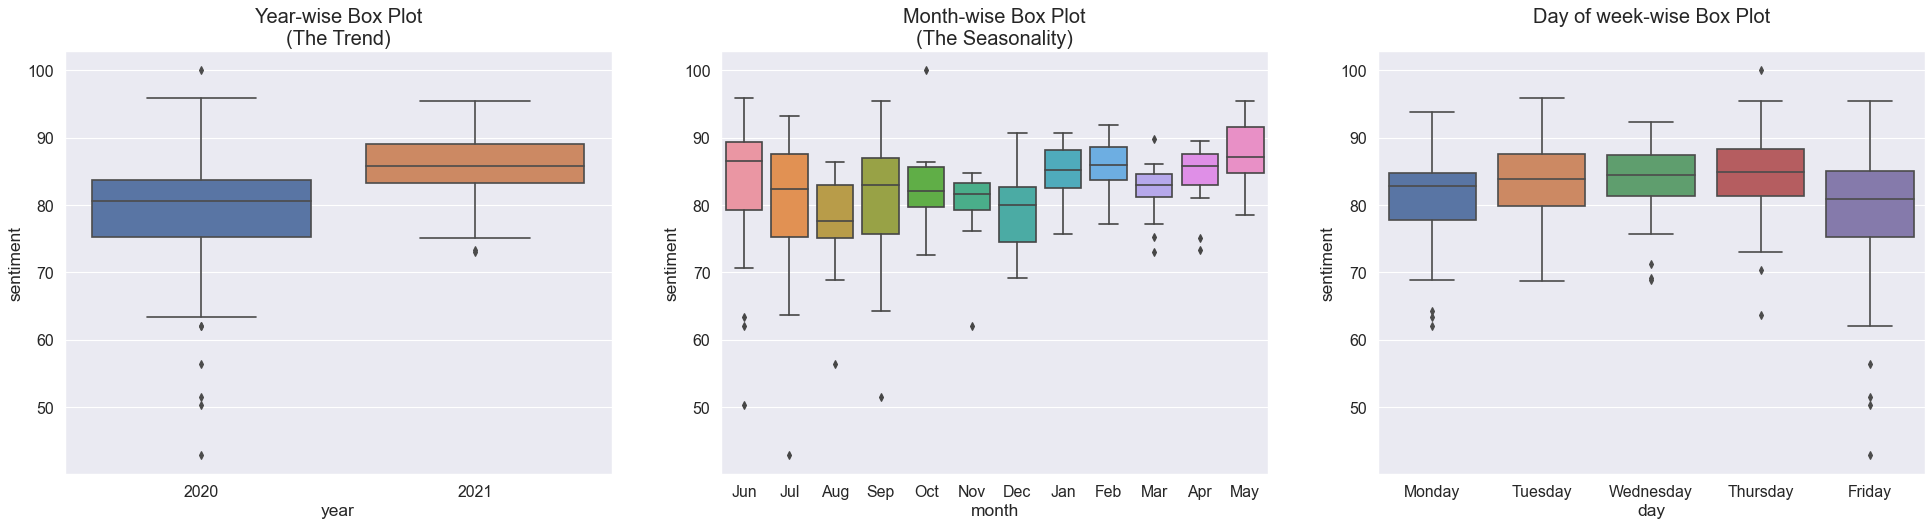

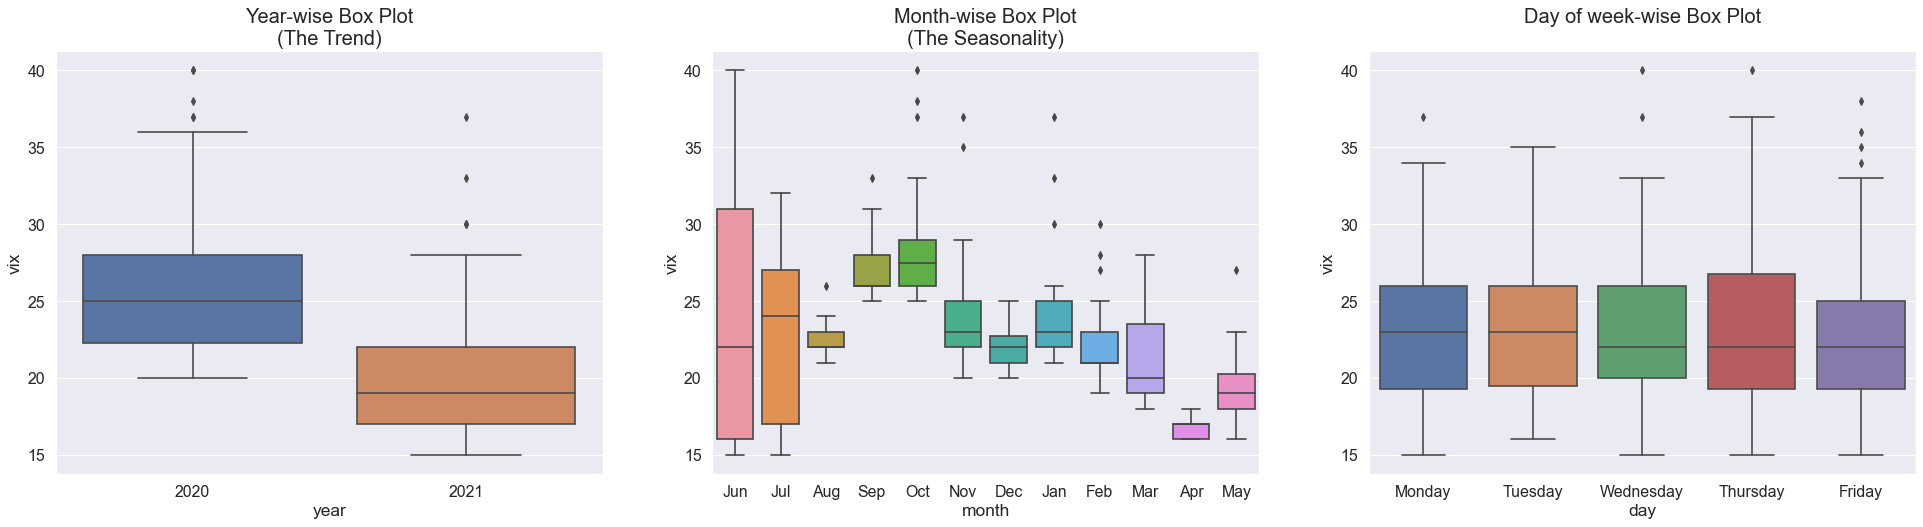

In [404]:
import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()]  #'Wednesday'


# Prepare data
df_part3['year'] = [d.year for d in df_part3.index]
df_part3['month'] = [d.strftime('%b') for d in df_part3.index]
df_part3['day'] = [d for d in df_part3.index.day_name()]
# # df_part3['date']
years = df_part3['year'].unique()

# Draw Plot
fig, axes = plt.subplots(1, 3, figsize=(30,7), dpi= 80)
sns.boxplot(x='year', y='sentiment', data=df_part3, ax=axes[0])
sns.boxplot(x='month', y='sentiment', data=df_part3, ax=axes[1])# data=df.loc[~df.year.isin([1991, 2008]), :])
sns.boxplot(x='day', y='sentiment', data=df_part3, ax=axes[2])# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
#plt.title("Sentiment Trend and Seasonality Analysis", fontsize=18); 
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
axes[2].set_title('Day of week-wise Box Plot\n', fontsize=18)

plt.show()

# Draw Plot
fig, axes = plt.subplots(1, 3, figsize=(30,7), dpi= 80)
sns.boxplot(x='year', y='vix', data=df_part3, ax=axes[0])
sns.boxplot(x='month', y='vix', data=df_part3, ax=axes[1])# data=df.loc[~df.year.isin([1991, 2008]), :])
sns.boxplot(x='day', y='vix', data=df_part3, ax=axes[2])# data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
#plt.title("Sentiment Trend and Seasonality Analysis", fontsize=18); 
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
axes[2].set_title('Day of week-wise Box Plot\n', fontsize=18)

plt.show()

In [405]:
# def cor_reg_kde(x,y,data):
#     # Correlation coefficient
#     #print('correlation coefficient:',corr.loc[x,y])
    
#     # Subplot adjust
#     plt.subplots_adjust(wspace=0.5)
    
#     # Plot (regression and kernel density)
#     fig,(ax1,ax2) = plt.subplots(1,2,figsize=(10,5))
#     sns.regplot(x,y,data=data,ax=ax1)
#     sns.kdeplot(data[[x]],data[y],shade=True,ax=ax2)
    
# cor_reg_kde('pos','VIX',df)
# # cor_reg_kde('Indiv_Put_Netbuying_Quantity','Open_interest',df)
# # cor_reg_kde('Indiv_Put_Netbuying_Quantity','Indiv_Call_Netbuying_Quantity',df)
# # cor_reg_kde('Indiv_Call_Netbuying_Quantity','Open_interest',df)

In [406]:
# # Checking date for empty strings
# for date, row in df_vix.T.iteritems():
#     if type(df_vix.loc[date, 'articles']).__name__ == 'str':
#         print(date)

In [407]:
# df

In [408]:
#df_vixs=df[['VIX']]
df_vixs=df
# df_vixs.plot(x="date", y="sentiment", kind="scatter")
# target_dist = sns.factorplot(x="VIX", data=df_vixs, kind="count", size=10, aspect=1.5, palette="PuBuGn_d")
# plt.show();
# target_dist.savefig('/Users/Farid Srouji/Documents/Research/VIX prediction/master/financialmodelingprep/images/VIX_Histogram.png')

In [409]:
df[['sentiment']].round()

,sentiment
2019-09-25,88.0
2019-09-26,84.0
2019-09-27,76.0
2019-09-30,84.0
2019-10-01,79.0
...,...
2021-07-12,91.0
2021-07-13,93.0
2021-07-14,92.0
2021-07-15,91.0


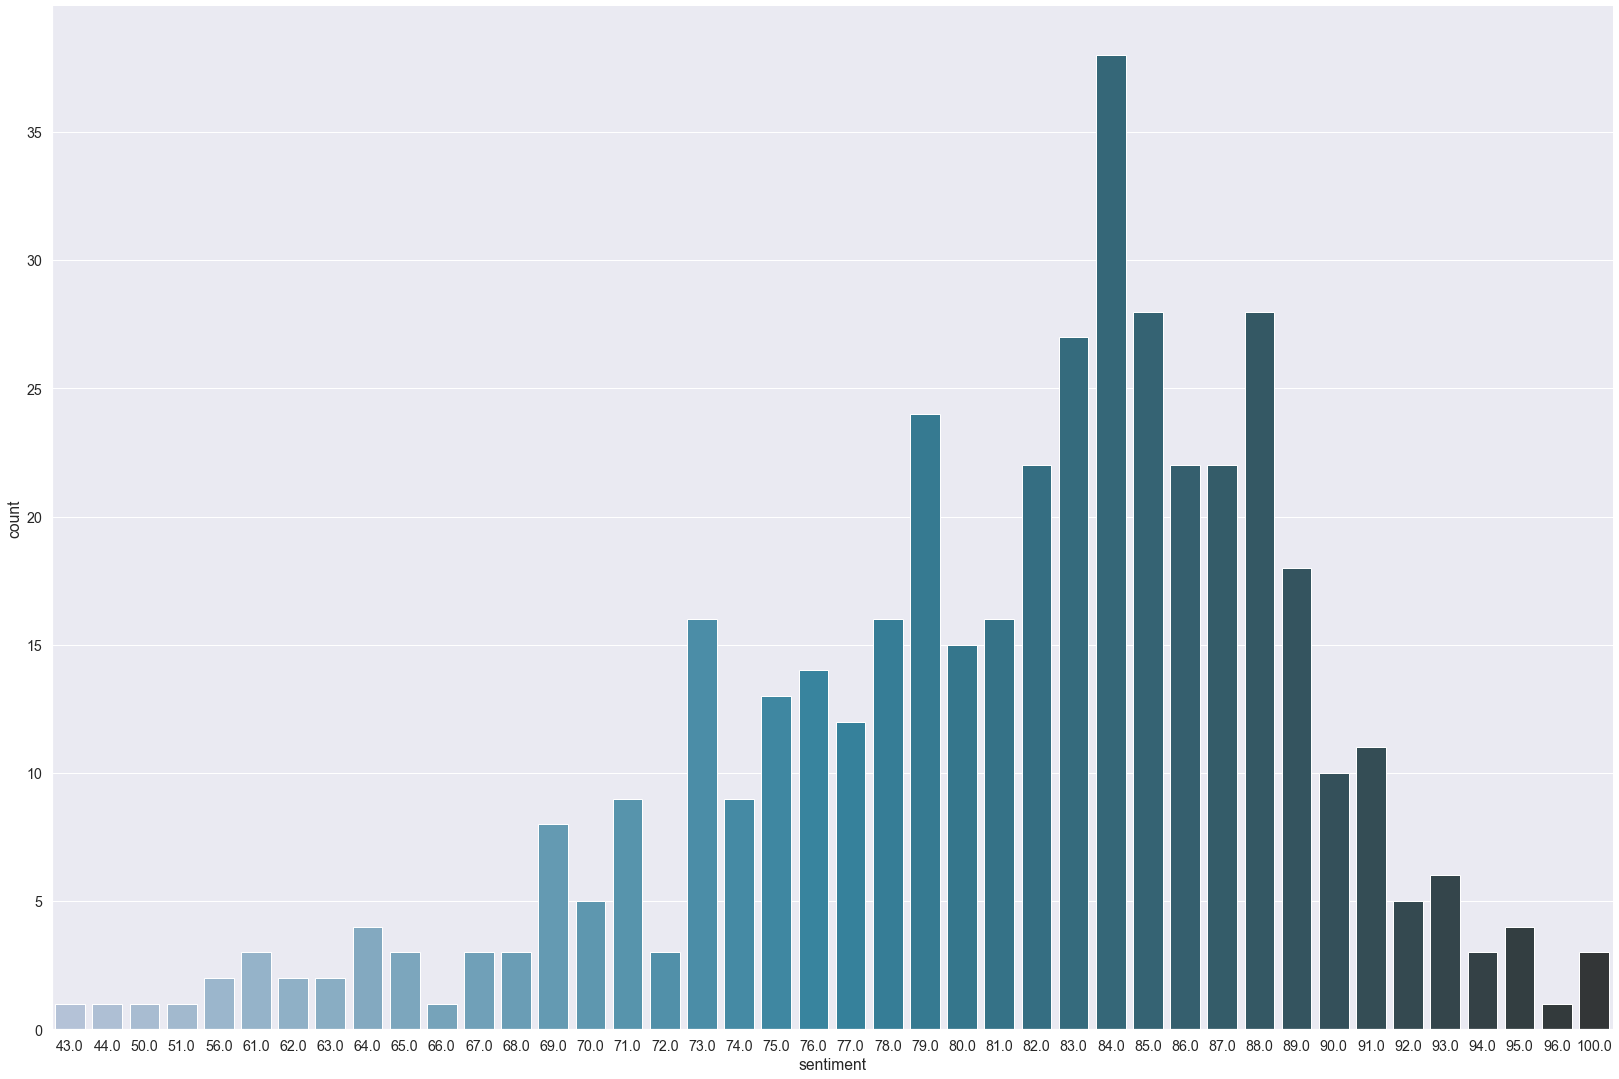

In [410]:
target_dist = sns.factorplot(x="sentiment", data=df[['sentiment']].round(0), kind="count", size=15, aspect=1.5, palette="PuBuGn_d")
plt.show();
target_dist.savefig('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/sentiment_Histogram.png')

In [411]:
#show_dist(df_vixs, 'VIX')

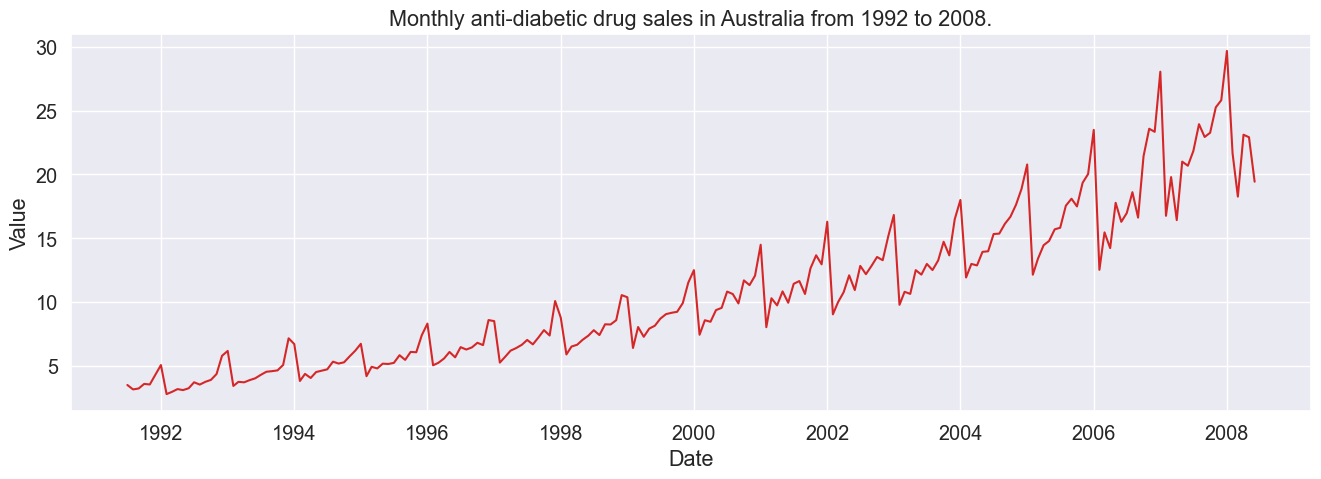

In [412]:
# Time series data source: fpp pacakge in R.
import matplotlib.pyplot as plt
df = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/a10.csv', parse_dates=['date'], index_col='date')

# Draw Plot
def plot_df(df, x, y, title="", xlabel='Date', ylabel='Value', dpi=100):
    plt.figure(figsize=(16,5), dpi=dpi)
    plt.plot(x, y, color='tab:red')
    plt.gca().set(title=title, xlabel=xlabel, ylabel=ylabel)
    plt.show()

plot_df(df, x=df.index, y=df.value, title='Monthly anti-diabetic drug sales in Australia from 1992 to 2008.')    

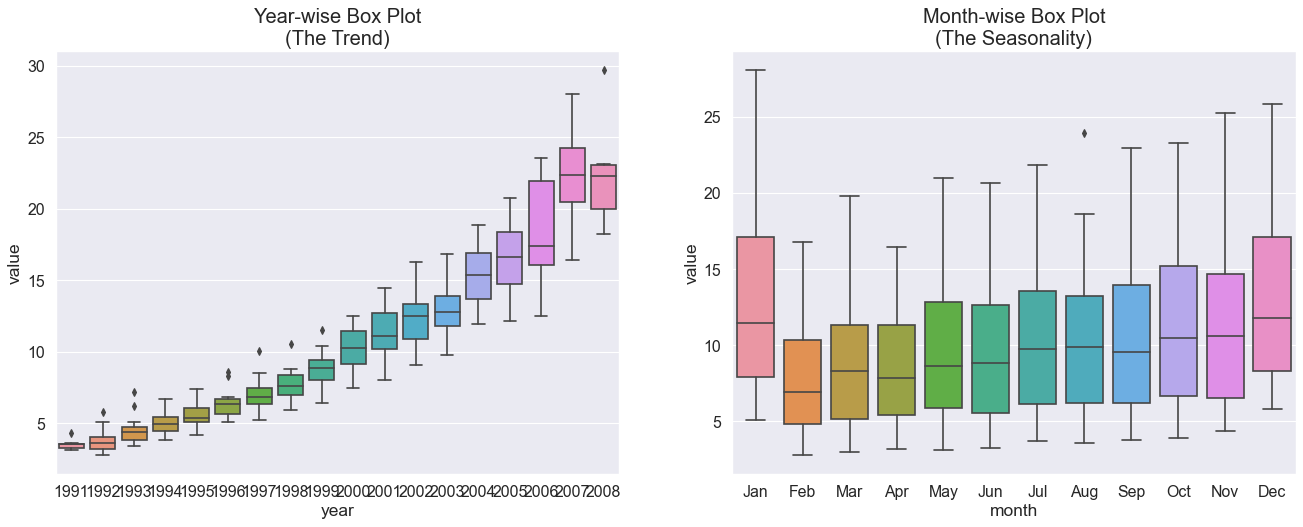

In [413]:
# Import Data
df = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/a10.csv', parse_dates=['date'], index_col='date')
df.reset_index(inplace=True)

# Prepare data
df['year'] = [d.year for d in df.date]
df['month'] = [d.strftime('%b') for d in df.date]
years = df['year'].unique()

# Draw Plot
fig, axes = plt.subplots(1, 2, figsize=(20,7), dpi= 80)
sns.boxplot(x='year', y='value', data=df, ax=axes[0])
sns.boxplot(x='month', y='value', data=df.loc[~df.year.isin([1991, 2008]), :])

# Set Title
axes[0].set_title('Year-wise Box Plot\n(The Trend)', fontsize=18); 
axes[1].set_title('Month-wise Box Plot\n(The Seasonality)', fontsize=18)
plt.show()

<AxesSubplot:title={'center':'Trend and Seasonality'}, xlabel='date'>

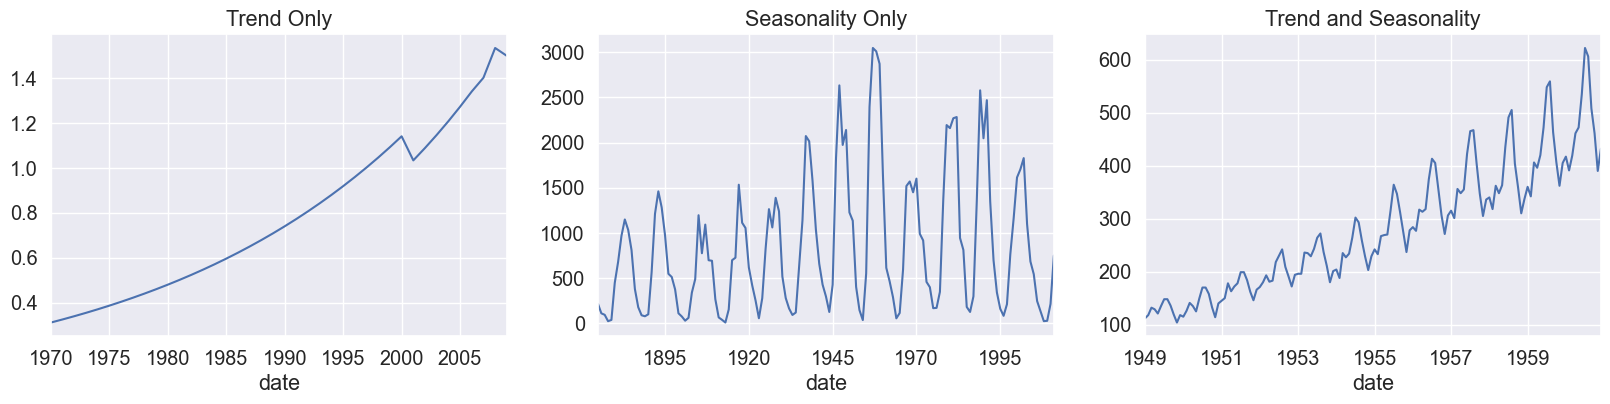

In [414]:
fig, axes = plt.subplots(1,3, figsize=(20,4), dpi=100)
pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/guinearice.csv', parse_dates=['date'], index_col='date').plot(title='Trend Only', legend=False, ax=axes[0])

pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/sunspotarea.csv', parse_dates=['date'], index_col='date').plot(title='Seasonality Only', legend=False, ax=axes[1])

pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/AirPassengers.csv', parse_dates=['date'], index_col='date').plot(title='Trend and Seasonality', legend=False, ax=axes[2])